# Google Advance Data Analytics Capstone Project
### Providing data-driven suggestions for HR

## Description and deliverables

This capstone project is an opportunity for you to analyze a dataset and build predictive models that can provide insights to the Human Resources (HR) department of a large consulting firm.

Upon completion, you will have two artifacts that you will be able to present to future employers. One is a brief one-page summary of this project that you will present to external stakeholders as the data professional in Salifort Motors. The other is a complete code notebook provided here. Based on your prior coursework, select one method to complete this project: use either a regression model or a machine learning model to predict whether an employee will leave the company. The exemplar following this actiivty shows both approaches, but you only need to do one.

In your deliverables, you will include the model evaluation (and interpretation if applicable), a data visualization(s) of your choice that is directly related to the question you ask, ethical considerations, and the resources you used to troubleshoot and find answers or solutions.


# **PACE stages**


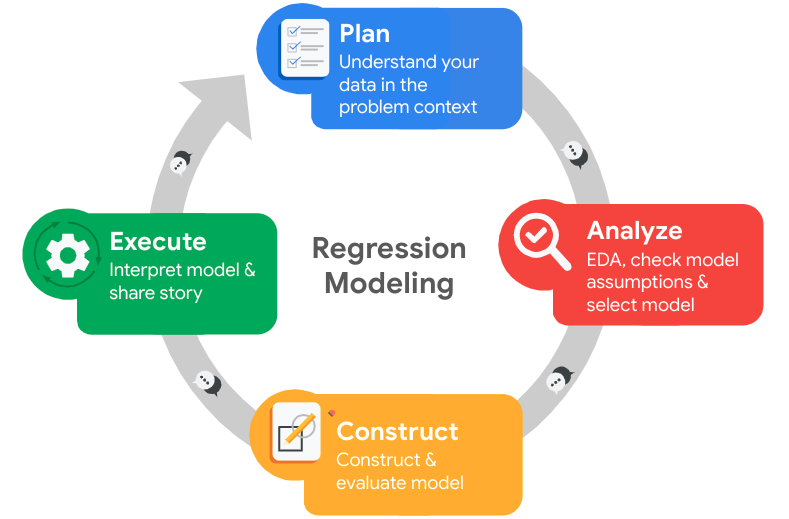

## **Pace: Plan**

Consider the questions in your PACE Strategy Document to reflect on the Plan stage.

In this stage, consider the following:

### Understand the business scenario and problem

The HR department at Salifort Motors wants to take some initiatives to improve employee satisfaction levels at the company. They collected data from employees, but now they don’t know what to do with it. They refer to you as a data analytics professional and ask you to provide data-driven suggestions based on your understanding of the data. They have the following question: what’s likely to make the employee leave the company?

Your goals in this project are to analyze the data collected by the HR department and to build a model that predicts whether or not an employee will leave the company.

If you can predict employees likely to quit, it might be possible to identify factors that contribute to their leaving. Because it is time-consuming and expensive to find, interview, and hire new employees, increasing employee retention will be beneficial to the company.

### Familiarize yourself with the HR dataset

The dataset that you'll be using in this lab contains 15,000 rows and 10 columns for the variables listed below. 

**Note:** you don't need to download any data to complete this lab. For more information about the data, refer to its source on [Kaggle](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction?select=HR_comma_sep.csv).

Variable  |Description |
-----|-----|
satisfaction_level|Employee-reported job satisfaction level [0&ndash;1]|
last_evaluation|Score of employee's last performance review [0&ndash;1]|
number_project|Number of projects employee contributes to|
average_monthly_hours|Average number of hours employee worked per month|
time_spend_company|How long the employee has been with the company (years)
Work_accident|Whether or not the employee experienced an accident while at work
left|Whether or not the employee left the company
promotion_last_5years|Whether or not the employee was promoted in the last 5 years
Department|The employee's department
salary|The employee's salary (U.S. dollars)

💭
### Reflect on these questions as you complete the plan stage.

Who are your stakeholders for this project?\
HR Department
<br><br>
What are you trying to solve or accomplish?\
Predict employee will leave the company or not, and identify the possible contributing factors so we can focus on that particular issue.
<br><br>
What are your initial observations when you explore the data?\
Searching through duplicates in records, handle missing values, distribution of data, and manage outliers.
<br><br>
What resources do you find yourself using as you complete this stage?\
Basic library packages, such as numpy and pandas.
<br><br>
Do you have any ethical considerations in this stage?\
Employees' name should not be included, and their superiors/subordinates. 

## Step 1. Imports

*   Import packages
*   Load dataset



### Import packages

In [1]:
# Import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load dataset

`Pandas` is used to read a dataset called **`HR_capstone_dataset.csv`.**  As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [2]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)

In [3]:
# RUN THIS CELL TO IMPORT YOUR DATA. 

# Load dataset into a dataframe
path = ''
df = pd.read_csv(path + "HR_capstone_dataset.csv")

# Display first few rows of the dataframe
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


## Step 2. Data Exploration (Initial EDA and data cleaning)

- Understand your variables
- Clean your dataset (missing data, redundant data, outliers)



### Gather basic information about the data

In [4]:
# Gather basic information about the data
print('df Shape:' , df.shape,'\n') 
print(df.columns)

df Shape: (14999, 10) 

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'Department', 'salary'],
      dtype='str')


### Gather descriptive statistics about the data

In [5]:
# Gather descriptive statistics about the data
df.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


### Rename columns

As a data cleaning step, rename the columns as needed. Standardize the column names so that they are all in `snake_case`, correct any column names that are misspelled, and make column names more concise as needed.

In [6]:
# Rename columns as needed
df = df.rename(columns={
    'Work_accident' : 'work_accident', 'Department' : 'department'})

# Display all column names after the update
df.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'work_accident', 'left',
       'promotion_last_5years', 'department', 'salary'],
      dtype='str')

### Check missing values

Check for any missing values in the data.

In [7]:
# Check for missing values
print('Null rows: ', df.isna().sum(),'\n')

Null rows:  satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
work_accident            0
left                     0
promotion_last_5years    0
department               0
salary                   0
dtype: int64 



### Check duplicates

Check for any duplicate entries in the data.

In [8]:
# Check for duplicates
print('Duplicated rows: ', df.duplicated().sum(),'\n')

Duplicated rows:  3008 



In [9]:
# Inspect some rows containing duplicates as needed
df[df.duplicated()==True].head(10)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,work_accident,left,promotion_last_5years,department,salary
396,0.46,0.57,2,139,3,0,1,0,sales,low
866,0.41,0.46,2,128,3,0,1,0,accounting,low
1317,0.37,0.51,2,127,3,0,1,0,sales,medium
1368,0.41,0.52,2,132,3,0,1,0,RandD,low
1461,0.42,0.53,2,142,3,0,1,0,sales,low
1516,0.40,0.50,2,127,3,0,1,0,IT,low
1616,0.37,0.46,2,156,3,0,1,0,sales,low
1696,0.39,0.56,2,160,3,0,1,0,sales,low
1833,0.10,0.85,6,266,4,0,1,0,sales,low
12000,0.38,0.53,2,157,3,0,1,0,sales,low


In [10]:
# Drop duplicates and save resulting dataframe in a new variable as needed
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(11991, 10)

### Check unique values

In [11]:
#Unique Values from Dataset
Unique_Dict = {
    'columns' : [],
    'unique_count' : [],
    'unique' : [],
    'dtype' : []
}

for idx in range( len(df.columns) ) :
    Unique_Dict['columns'].append(df.columns[idx])
    Unique_Dict['unique_count'].append(df[df.columns[idx]].nunique())
    if (df[df.columns[idx]].nunique()) < 20:
        Unique_Dict['unique'].append(df[df.columns[idx]].unique())
    else:
        Unique_Dict['unique'].append('More than 20')
    Unique_Dict['dtype'].append(df.dtypes.iloc[idx])

pd.DataFrame(Unique_Dict)

,columns,unique_count,unique,dtype
0,satisfaction_level,92,More than 20,float64
1,last_evaluation,65,More than 20,float64
2,number_project,6,"[2, 5, 7, 6, 4, 3]",int64
3,average_montly_hours,215,More than 20,int64
4,time_spend_company,8,"[3, 6, 4, 5, 2, 8, 10, 7]",int64
5,work_accident,2,"[0, 1]",int64
6,left,2,"[1, 0]",int64
7,promotion_last_5years,2,"[0, 1]",int64
8,department,10,"[sales, accounting, hr, technical, support, management, IT, product_mng, marketing, RandD]",str
9,salary,3,"[low, medium, high]",str


### Check outliers

Check for outliers in the data.

<Axes: xlabel='last_evaluation', ylabel='Count'>

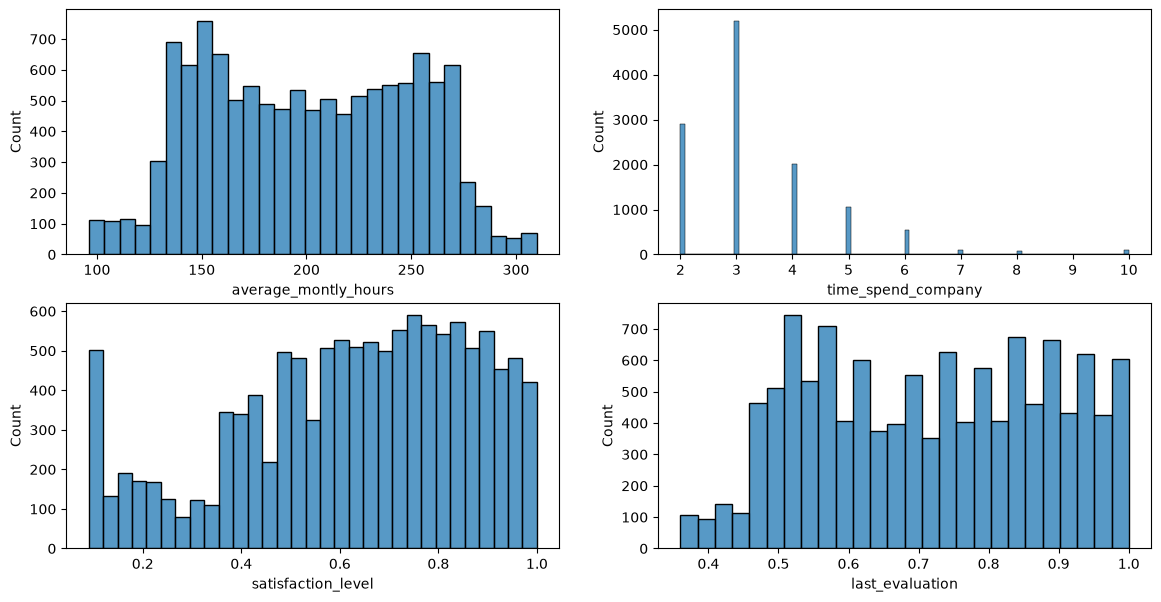

In [12]:
# Create a boxplot to visualize distribution and detect any outliers
fig, axes = plt.subplots(2,2,figsize=(14,7))

sns.histplot(data=df, x='average_montly_hours', ax=axes[0,0])
sns.histplot(data=df, x='time_spend_company', ax=axes[0,1])
sns.histplot(data=df, x='satisfaction_level', ax=axes[1,0])
sns.histplot(data=df, x='last_evaluation', ax=axes[1,1])

In [13]:
# Determine the number of rows containing outliers
df[df['time_spend_company']>5]

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,work_accident,left,promotion_last_5years,department,salary
1,0.80,0.86,5,262,6,0,1,0,sales,medium
17,0.78,0.99,4,255,6,0,1,0,sales,low
34,0.84,0.87,4,246,6,0,1,0,hr,low
47,0.57,0.70,3,273,6,0,1,0,support,low
67,0.90,0.98,4,264,6,0,1,0,product_mng,medium
...,...,...,...,...,...,...,...,...,...,...
11985,0.22,0.94,3,193,10,0,0,1,management,high
11986,0.90,0.55,3,259,10,1,0,1,management,high
11987,0.74,0.95,5,266,10,0,0,1,management,high
11988,0.85,0.54,3,185,10,0,0,1,management,high


Certain types of models are more sensitive to outliers than others. When you get to the stage of building your model, consider whether to remove outliers, based on the type of model you decide to use.

### Check Correlation

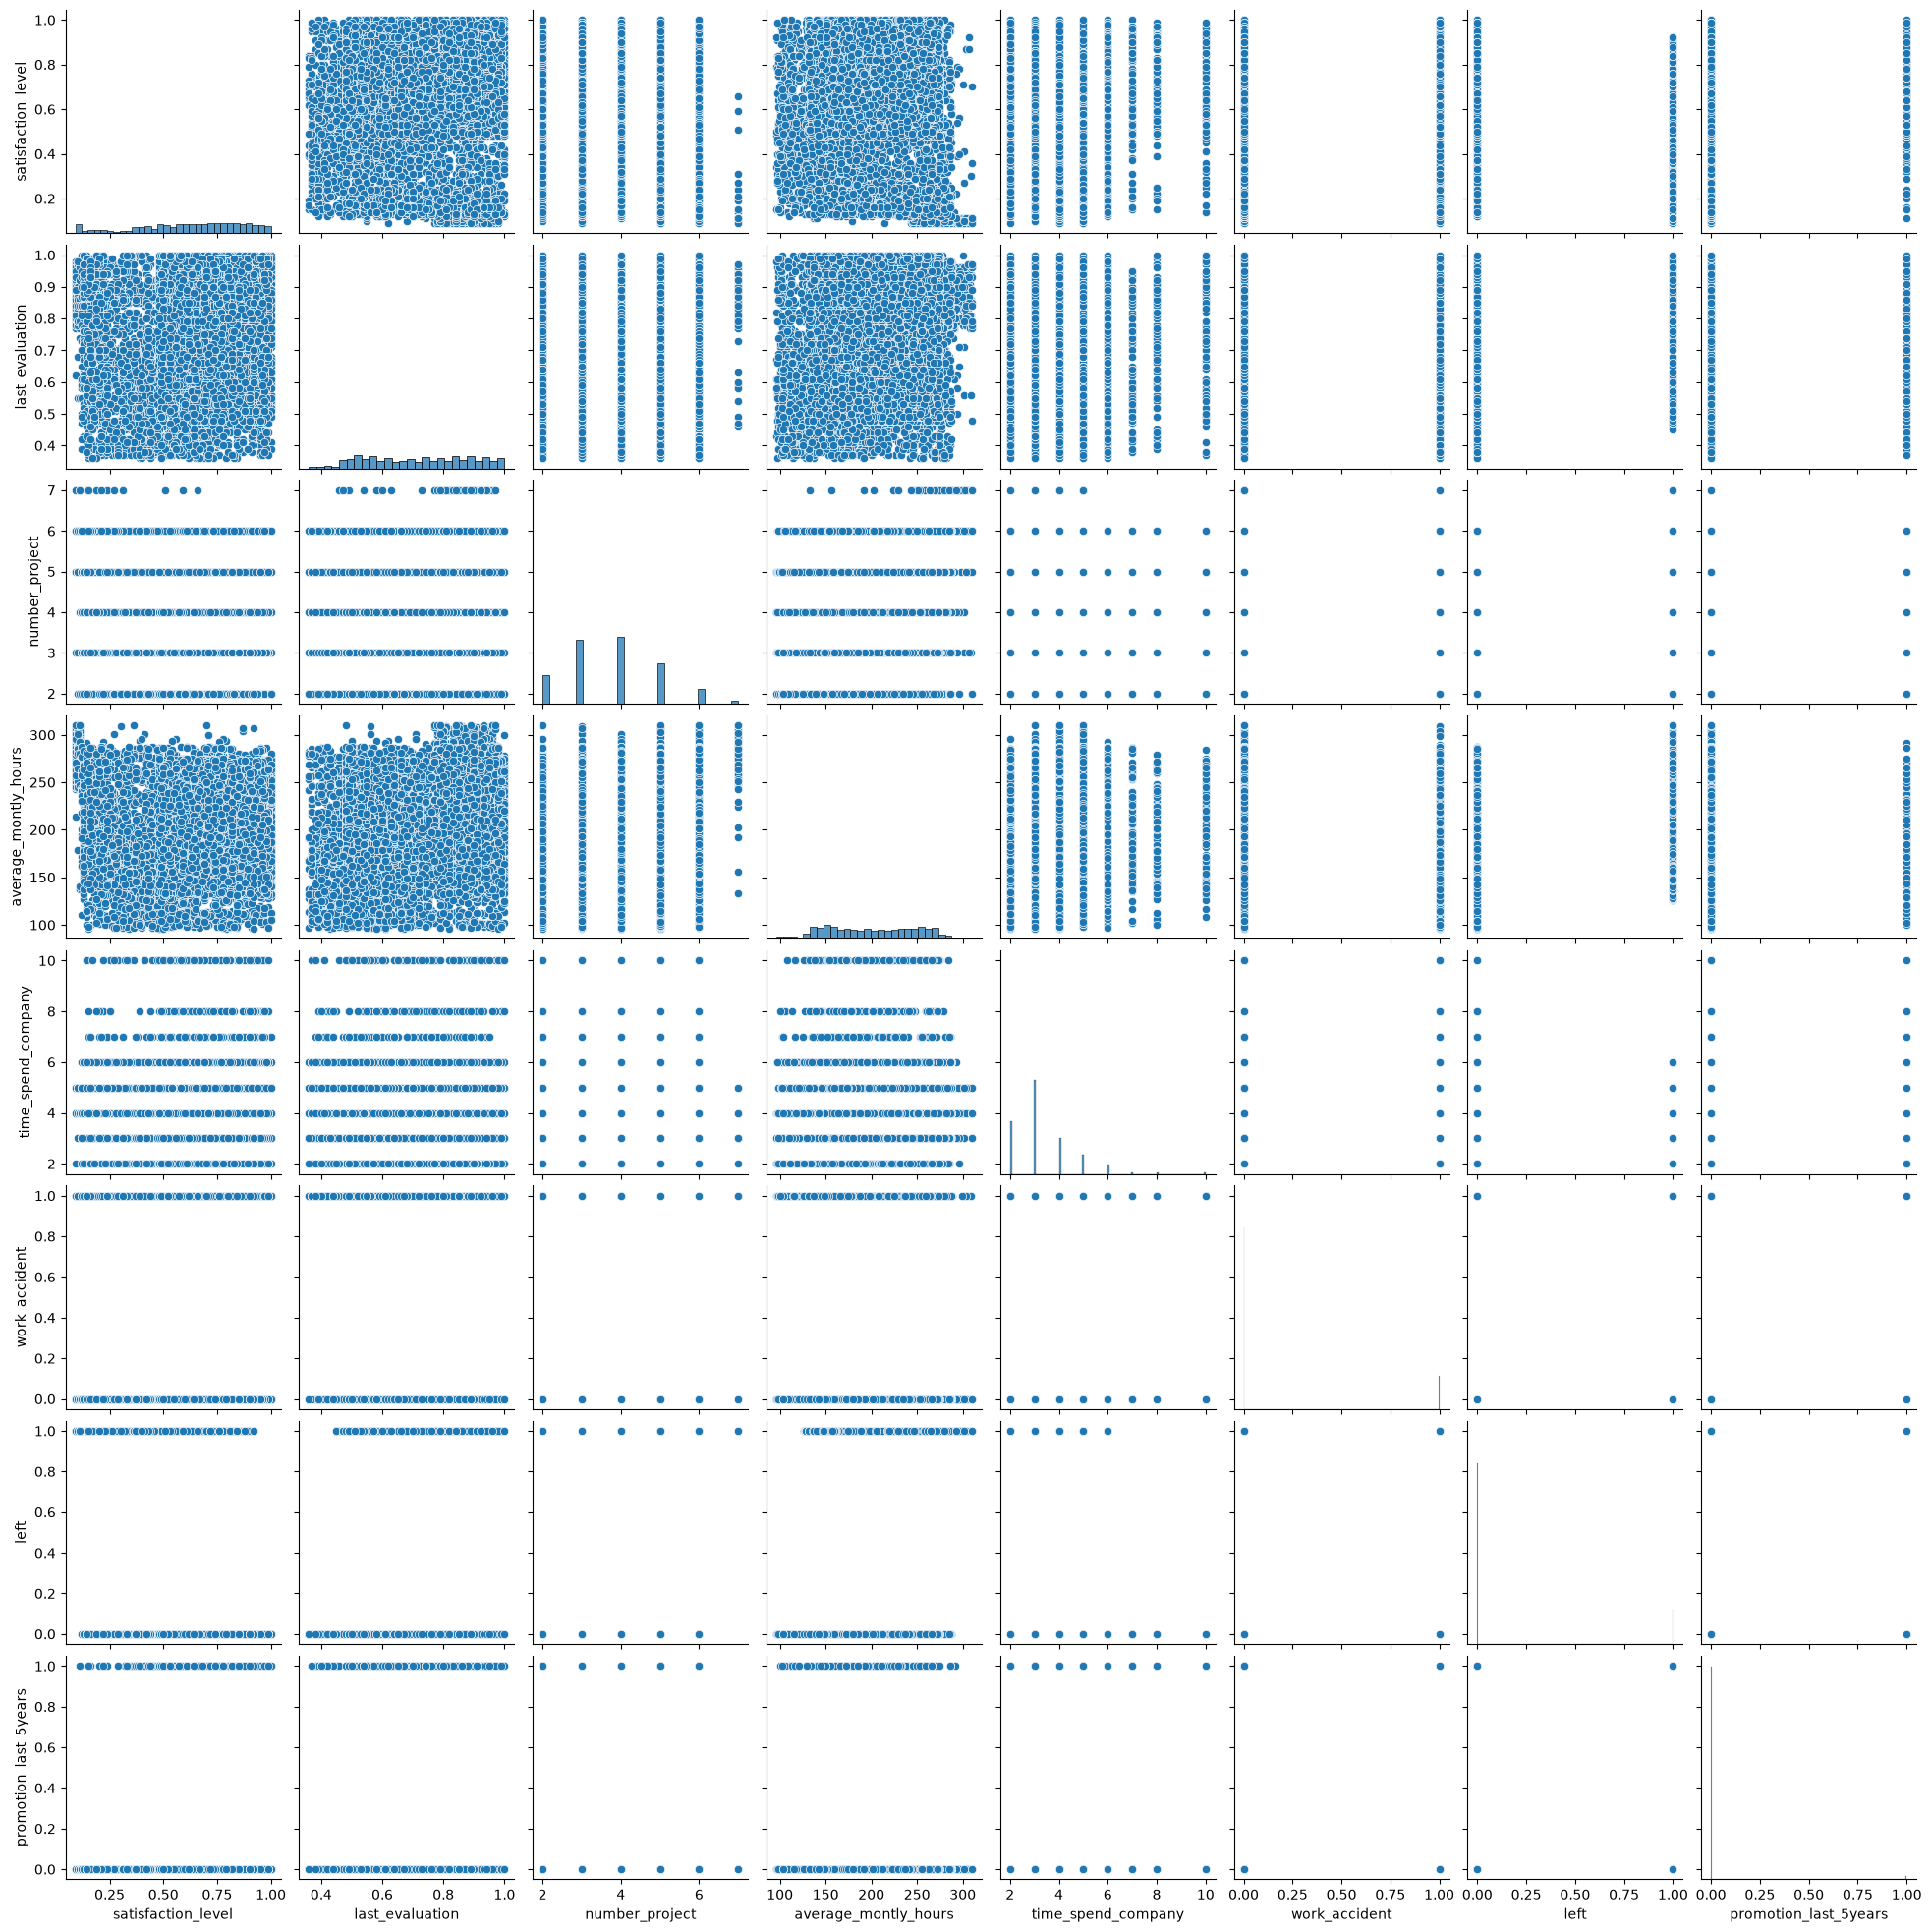

In [14]:
sns.pairplot(data=df)
# No pattern detected

# Pace: Analyze Stage
- Perform EDA (analyze relationships between variables)



## Step 2. Data Exploration (Continue EDA)

Begin by understanding how many employees left and what percentage of all employees this figure represents.

In [15]:
# Get numbers of people who left vs. stayed
print ( df['left'].value_counts() ) 

# Get percentages of people who left vs. stayed
print ( df['left'].value_counts() / len(df['left']) * 100 ) 

left
0    10000
1     1991
Name: count, dtype: int64
left
0    83.39588
1    16.60412
Name: count, dtype: float64


### Data visualizations

Now, examine variables that you're interested in, and create plots to visualize relationships between variables in the data.

In [16]:
df.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'work_accident', 'left',
       'promotion_last_5years', 'department', 'salary'],
      dtype='str')

In [17]:
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


<Axes: xlabel='time_spend_company'>

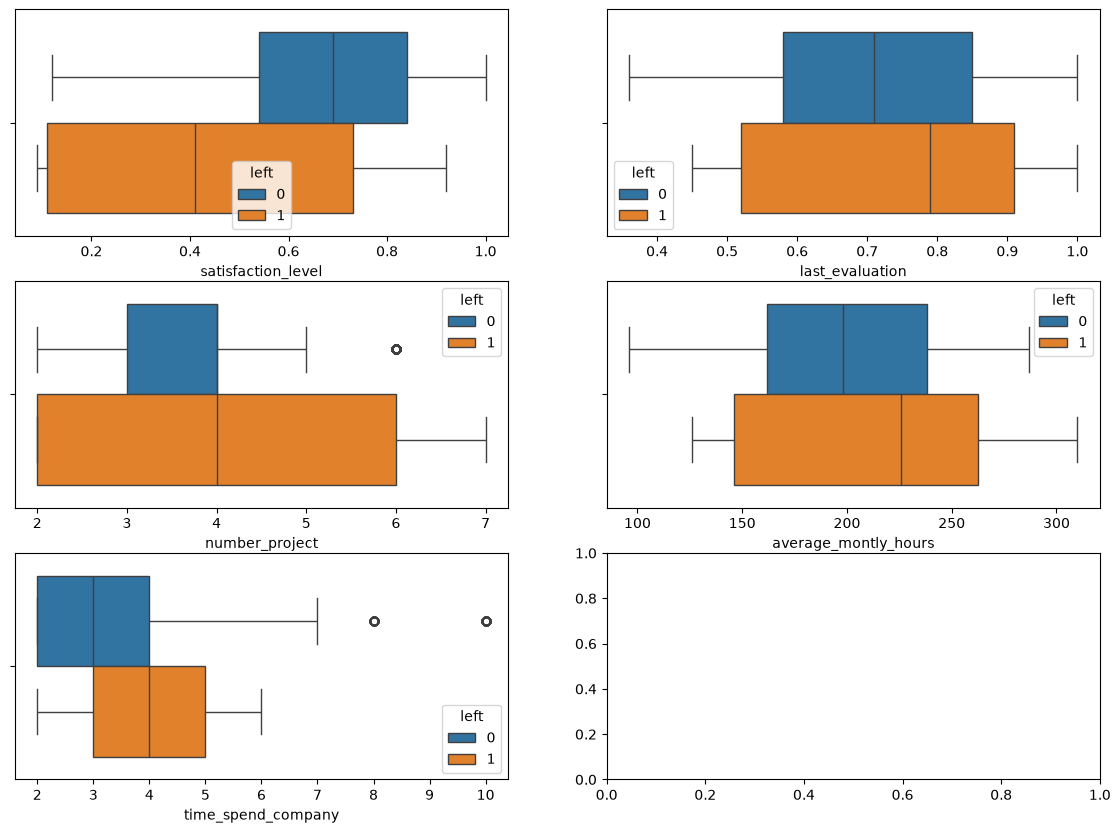

In [18]:
# Distribution of 'satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company'
# with people who left vs. stayed

# Create a plot as needed
fig, axes = plt.subplots(3,2, figsize=(14,10))

sns.boxplot(data=df, x='satisfaction_level', hue='left', ax=axes[0,0])
sns.boxplot(data=df, x='last_evaluation', hue='left', ax=axes[0,1])
sns.boxplot(data=df, x='number_project', hue='left', ax=axes[1,0])
sns.boxplot(data=df, x='average_montly_hours', hue='left', ax=axes[1,1])
sns.boxplot(data=df, x='time_spend_company', hue='left', ax=axes[2,0])


<Axes: xlabel='promotion_last_5years', ylabel='count'>

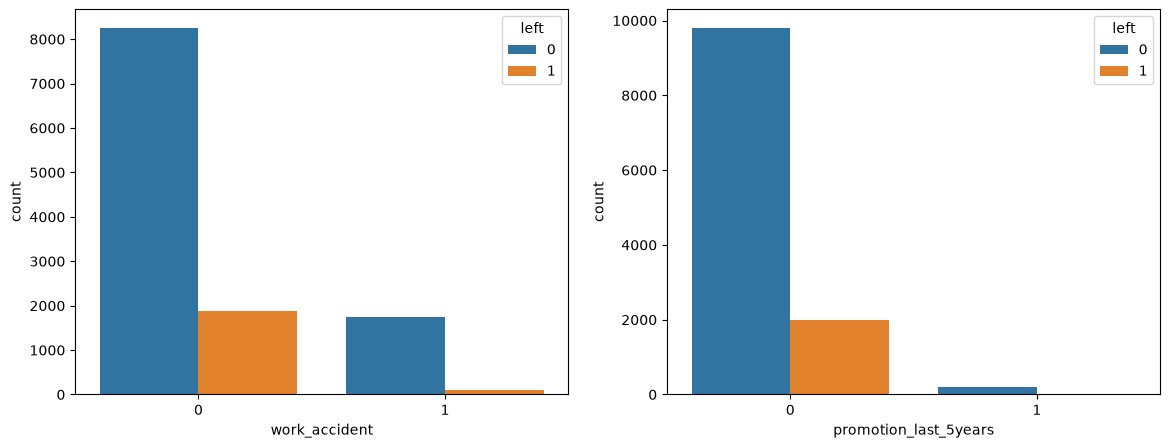

In [19]:
# Distribution of 'work_accident', 'promotion_last_5years'
# with people who left vs. stayed

fig, axes = plt.subplots(1,2, figsize=(14,5))

sns.countplot(data=df, x='work_accident', hue='left', ax=axes[0])
sns.countplot(data=df, x='promotion_last_5years', hue='left', ax=axes[1])

<Axes: xlabel='left', ylabel='count'>

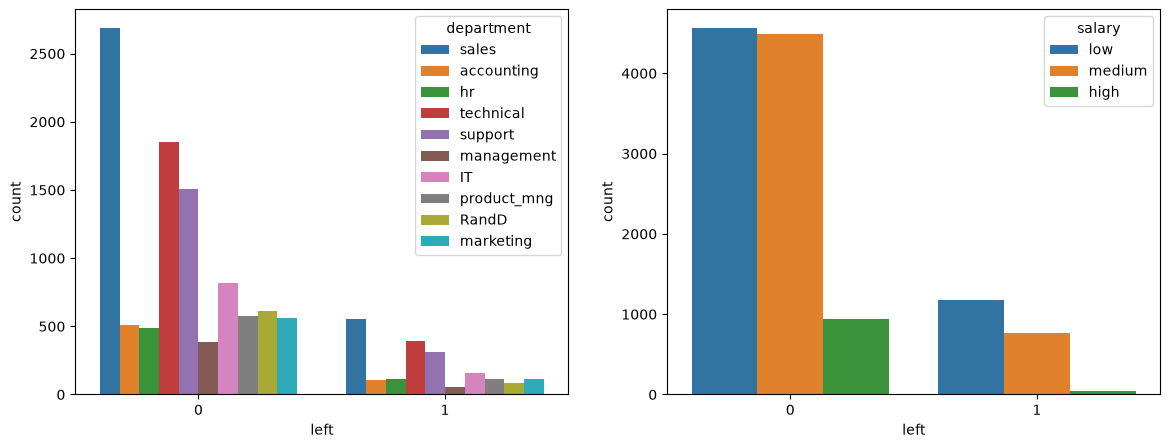

In [20]:
# Distribution of 'department', 'salary'
# with people who left vs. stayed

fig, axes = plt.subplots(1,2, figsize=(14,5))

sns.countplot(data=df, hue='department', x='left', ax=axes[0])
sns.countplot(data=df, hue='salary', x='left', ax=axes[1])


<Axes: >

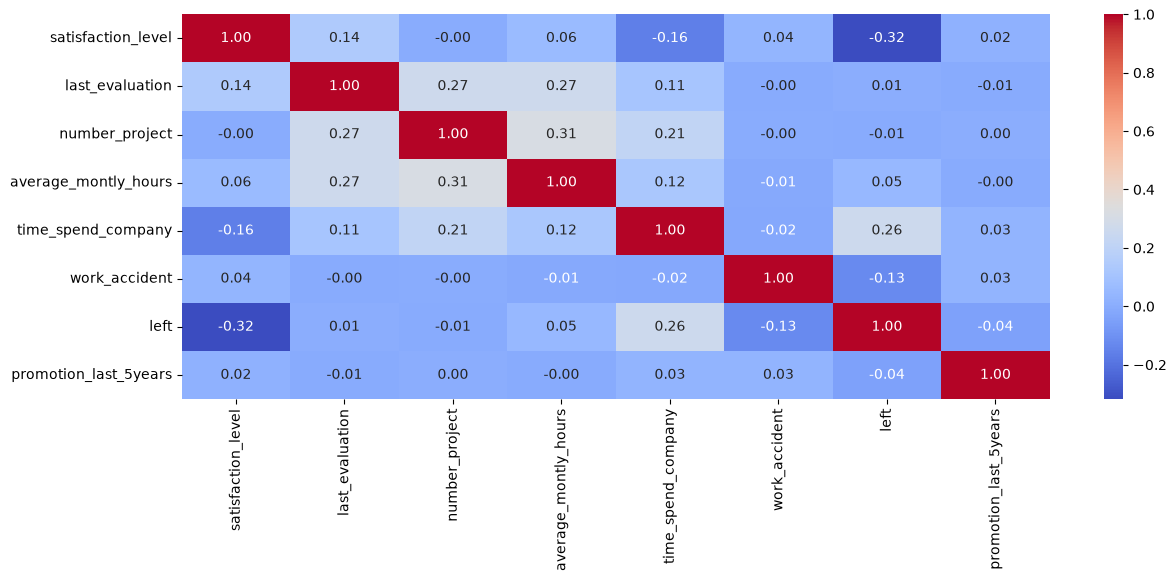

In [25]:
# Correlation between variables

corr_matrix = df.corr(numeric_only=True, method='spearman')
plt.figure(figsize=(14, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

Based on correlation heatmap,\
`satisfaction_level`, `number_project` and `average_monthly_hours` has correlation.

<Axes: xlabel='number_project', ylabel='average_montly_hours'>

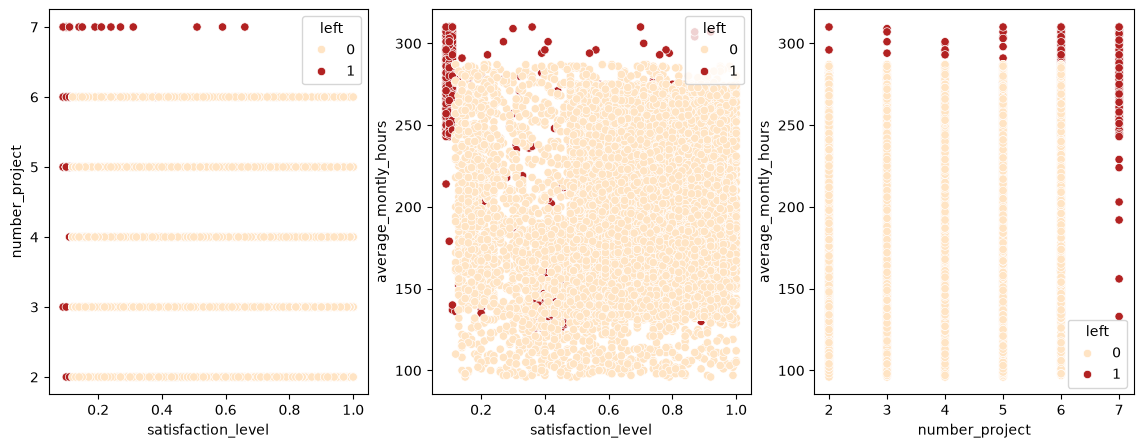

In [36]:
# Correlation Satisfaction level and other variable

fig, axes = plt.subplots(1,3, figsize=(14,5))
ColorMap = {0:'bisque', 1:'firebrick'}

sns.scatterplot(data=df, x='satisfaction_level', y='number_project', hue='left', palette=ColorMap, ax=axes[0])
sns.scatterplot(data=df, x='satisfaction_level', y='average_montly_hours', hue='left', palette=ColorMap, ax=axes[1])
sns.scatterplot(data=df, x='number_project', y='average_montly_hours', hue='left', palette=ColorMap, ax=axes[2])

Based on the scatter plot,\
it is known that employee who have low satisfaction level, associated with high number of project and high average monthly hours.\
Employee who left the company, either they have high number of projects or high working hours.

In [20]:
df['left'].value_counts() / len(df['left'])
# Imbalanced Dataset

left
0    0.833959
1    0.166041
Name: count, dtype: float64

💭
### Reflect on these questions as you complete the analyze stage.

What insights can you gather from the plots you created to visualize the data?\
Several numeric variables, has different average/median from the 'Left' and 'Stayed' employee, which indicates there are difference between the group.\
As for categorical, such as 'Promotion', employee who are left, did not get promotion in 5 years.\
Also, employee with high salary, tend not to left.
<br><br>
What did you observe about the relationships between variables?\
Searching through specific pattern or group between the previous data; Left vs Stayed employees
<br><br>
What do you observe about the distributions in the data?\
The numeric variables are not normally distributed. 
<br><br>
What transformations did you make with your data? Why did you chose to make those decisions?\
Although there are several duplicates found, it is unknown whether there are several employees with the same records or not. It is suggested that "Masked Identification" included in the analysis.\
As for outliers in 'time_spend_company', it is essential to keep it, as it is major contributing factor towards the target 'Left' or 'Stayed'
<br><br>
What are some purposes of EDA before constructing a predictive model?\
EDA is to ensure the data is in good quality, do not contain extreme outliers, and without missing values before modeling. 
<br><br>
What resources do you find yourself using as you complete this stage?\
During exploration process, it is essential to use data visualizations and statistic tests to reconfirm the insights.
<br><br>
Do you have any ethical considerations in this stage?\
It is suggested that "Masked Identification" included in the analysis.


# Pace: Construct Stage
- Determine which models are most appropriate
- Construct the model
- Confirm model assumptions
- Evaluate model results to determine how well your model fits the data


## Step 3. Model Building
- Fit a model that predicts the outcome variable using two or more independent variables
- Check model assumptions
- Evaluate the model

### Identify the type of prediction task, and the types of models most appropriate for this task.

This task need Classification model.\
By using several algorithm in cross validation, we can determine which algorithm works better, and enhance it through hyperparameter tuning.

### Modeling

In [21]:
# data splitting
from sklearn.model_selection import train_test_split

# pipeline
from sklearn.pipeline import Pipeline

# encoding
from sklearn.preprocessing import OneHotEncoder

# binning
from sklearn.preprocessing import KBinsDiscretizer

# scaling
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

# column transformer
from sklearn.compose import ColumnTransformer

# cross validation
from sklearn.model_selection import cross_val_score, cross_validate

# hyperparameter tuning
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# modeling
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# modeling -> ensemble various type
from sklearn.ensemble import VotingClassifier, StackingClassifier

# modeling -> ensemble similar type
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# stratified KFold
from sklearn.model_selection import StratifiedKFold

# imbalanced
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# metrics
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, fbeta_score
from sklearn.metrics import make_scorer, get_scorer_names


In [22]:
pd.DataFrame(Unique_Dict)

,columns,unique_count,unique,dtype
0,satisfaction_level,92,More than 20,float64
1,last_evaluation,65,More than 20,float64
2,number_project,6,"[2, 5, 7, 6, 4, 3]",int64
3,average_montly_hours,215,More than 20,int64
4,time_spend_company,8,"[3, 6, 4, 5, 2, 8, 10, 7]",int64
5,work_accident,2,"[0, 1]",int64
6,left,2,"[1, 0]",int64
7,promotion_last_5years,2,"[0, 1]",int64
8,department,10,"[sales, accounting, hr, technical, support, management, IT, product_mng, marketing, RandD]",str
9,salary,3,"[low, medium, high]",str


In [23]:
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [24]:
# Define features and target
df.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'work_accident', 'left',
       'promotion_last_5years', 'department', 'salary'],
      dtype='str')

In [25]:
X = df.copy().drop(columns=['left'])
y = df['left']

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=13, stratify=y)

In [27]:
# Define Model Pipeline for Pre-processing data & Column Transform

transformer = ColumnTransformer([
    ('onehot_encoding', OneHotEncoder(handle_unknown='error'), ['department', 'salary'] ),
    ('scaler', RobustScaler(), ['average_montly_hours']),
    ('scale_or_none', RobustScaler(), ['number_project','time_spend_company'])
], remainder='passthrough') # Passthrough others

transformer

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot_encoding', ...), ('scaler', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_

In [28]:
# Define Machine Learning Algorithm with Default Parameters

mod_Log = LogisticRegression(class_weight='balanced')
mod_KNN = KNeighborsClassifier()
mod_Tree = DecisionTreeClassifier()

# ensemble various
mod_voting = VotingClassifier(estimators=[('clf1', mod_Log),
                                      ('clf2', mod_KNN),
                                      ('clf3', mod_Tree)])

mod_stacking = StackingClassifier(estimators=[('clf1', mod_Log),
                                          ('clf2', mod_KNN),
                                          ('clf3', mod_Tree)])

# ensemble similar
mod_bagging= BaggingClassifier(random_state=13, estimator=DecisionTreeClassifier(), n_estimators=100)
mod_rf = RandomForestClassifier(random_state=13)
mod_adaboost = AdaBoostClassifier(random_state=13)
mod_gboost = GradientBoostingClassifier(random_state=13)
mod_xgboost = XGBClassifier(random_state=13)

In [29]:
# Cross Validation without Resampling

list_model = [mod_Log, mod_KNN, mod_Tree, mod_voting, mod_stacking, mod_bagging, mod_rf, mod_adaboost, mod_gboost, mod_xgboost]
list_all_score = []
list_mean_score = []
list_std = []

skf = StratifiedKFold(n_splits=5)

for model in list_model:
    # pipeline
    pipe_prep_model =  Pipeline([
        ('preprocessing', transformer),
        ('modeling', model)
    ])

    # cross val
    crossval = cross_val_score(estimator=pipe_prep_model,
                    X = X_train,
                    y = y_train,
                    cv = skf,
                    scoring = 'f1')

    # recall
    list_all_score.append(crossval.round(2))
    list_mean_score.append(crossval.mean())
    list_std.append(crossval.std())


In [30]:
df_result = pd.DataFrame()
df_result['algorithm'] = list_model
df_result['all_score'] = list_all_score
df_result['mean_f1_score'] = list_mean_score
df_result['std_score'] = list_std

df_result.sort_values(['mean_f1_score','std_score'], ascending=[False,True])

,algorithm,all_score,mean_f1_score,std_score
5,"BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100,\n random_state=13)","[0.94, 0.96, 0.93, 0.97, 0.96]",0.951985,0.012719
6,RandomForestClassifier(random_state=13),"[0.94, 0.95, 0.93, 0.96, 0.96]",0.948383,0.011859
9,"XGBClassifier(base_score=None, booster=None, callbacks=None,\n colsample_bylevel=None, colsample_bynode=None,\n colsample_bytree=None, device=None, early_stopping_rounds=None,\n enable_categorical=True, eval_metric=None, feature_types=None,\n feature_weights=None, gamma=None, grow_policy=None,\n importance_type=None, interaction_constraints=None,\n learning_rate=None, max_bin=None, max_cat_threshold=None,\n max_cat_to_onehot=None, max_delta_step=None, max_depth=None,\n max_leaves=None, min_child_weight=None, missing=nan,\n monotone_constraints=None, multi_strategy=None, n_estimators=None,\n n_jobs=None, num_parallel_tree=None, ...)","[0.94, 0.95, 0.93, 0.96, 0.95]",0.947577,0.010518
8,GradientBoostingClassifier(random_state=13),"[0.94, 0.95, 0.93, 0.96, 0.96]",0.944973,0.010444
4,"StackingClassifier(estimators=[('clf1',\n LogisticRegression(class_weight='balanced')),\n ('clf2', KNeighborsClassifier()),\n ('clf3', DecisionTreeClassifier())])","[0.92, 0.92, 0.91, 0.93, 0.94]",0.925740,0.011970
2,DecisionTreeClassifier(),"[0.91, 0.92, 0.89, 0.92, 0.91]",0.909662,0.012418
3,"VotingClassifier(estimators=[('clf1',\n LogisticRegression(class_weight='balanced')),\n ('clf2', KNeighborsClassifier()),\n ('clf3', DecisionTreeClassifier())])","[0.85, 0.85, 0.84, 0.88, 0.89]",0.862835,0.018567
1,KNeighborsClassifier(),"[0.84, 0.84, 0.83, 0.85, 0.87]",0.845850,0.012036
7,AdaBoostClassifier(random_state=13),"[0.83, 0.78, 0.84, 0.78, 0.83]",0.809488,0.027093
0,LogisticRegression(class_weight='balanced'),"[0.54, 0.54, 0.52, 0.56, 0.56]",0.544750,0.014044


In [31]:
# Resampling method

smote = SMOTE()   # Resample only minority (churned customer)
rus_samp = RandomUnderSampler()
ros_samp = RandomOverSampler()

In [33]:
# Define pipeline for Hyperparameter Tuning

pipe_prep =  ImbPipeline([
        ('preprocessing', transformer),
        ('resampling', smote),
        ('modeling', mod_bagging)
    ])

# Hyperparam
hyperparam = {'modeling__n_estimators': range(10,51,10),
              'preprocessing__scaler': [MinMaxScaler(), StandardScaler(), RobustScaler()],
              'preprocessing__scale_or_none': [None, MinMaxScaler(), StandardScaler(), RobustScaler()],
              'resampling' :[None, smote, rus_samp, ros_samp]
             }

# Method: Random search
gridsearch = GridSearchCV(
    estimator = pipe_prep,
    cv = 5,
    n_jobs = -1,
    param_grid= hyperparam,
    scoring = 'f1'
)

In [34]:
%%time
gridsearch.fit(X_train, y_train)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
300 fits failed out of a total of 1200.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
300 fits failed with the following error:
Traceback (most recent call last):
  File "C:\ProgramData\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\ProgramData\anaconda3\Lib\site-packages\imblearn\pipeline.py", line 514, in fit
    Xt, yt = self._fit(X

CPU times: total: 13 s
Wall time: 52.6 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=13))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modeling__n_estimators': range(10, 51, 10), 'preprocessing__scale_or_none': [None, MinMaxScaler(), ...], 'preprocessing__scaler': [MinMaxScaler(), StandardScaler(), ...], 'resampling': [None, SMOTE(), ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cros

In [35]:
pd.DataFrame(gridsearch.cv_results_).sort_values(by = 'rank_test_score').head(3)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_modeling__n_estimators,param_preprocessing__scale_or_none,param_preprocessing__scaler,param_resampling,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
120,0.658337,0.064830,0.029582,0.007050,30,StandardScaler(),MinMaxScaler(),None,"{'modeling__n_estimators': 30, 'preprocessing__scale_or_none': StandardScaler(), 'preprocessing__scaler': MinMaxScaler(), 'resampling': None}",0.941176,0.959872,0.934853,0.964744,0.959612,0.952051,0.011777,1
124,0.628583,0.080015,0.030161,0.007770,30,StandardScaler(),StandardScaler(),None,"{'modeling__n_estimators': 30, 'preprocessing__scale_or_none': StandardScaler(), 'preprocessing__scaler': StandardScaler(), 'resampling': None}",0.941176,0.959872,0.934853,0.964744,0.959612,0.952051,0.011777,1
116,0.664756,0.053410,0.037658,0.004899,30,MinMaxScaler(),RobustScaler(),None,"{'modeling__n_estimators': 30, 'preprocessing__scale_or_none': MinMaxScaler(), 'preprocessing__scaler': RobustScaler(), 'resampling': None}",0.941176,0.959872,0.934853,0.964744,0.959612,0.952051,0.011777,1


In [36]:
# Define model after tuning
best_final_model = gridsearch.best_estimator_

# fit
best_final_model.fit(X_train, y_train)

# predict
y_pred = best_final_model.predict(X_test)

print('F1 score test: ', f1_score(y_test, y_pred) )
print('Recall score: ', recall_score(y_test, y_pred))

F1 score test:  0.9413298565840938
Recall score:  0.907035175879397


### Confusion Matrix

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

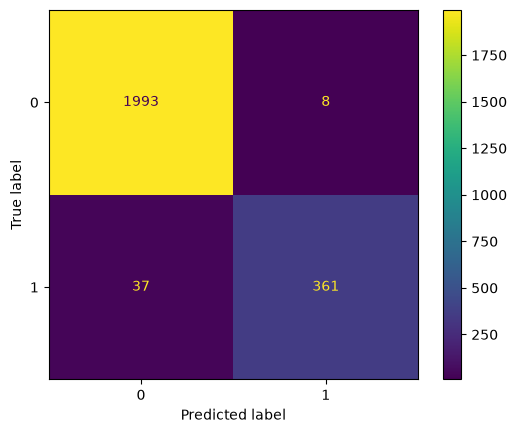

In [38]:
# After tuning
cm = confusion_matrix(y_test, y_pred)
cm_disp = ConfusionMatrixDisplay(confusion_matrix=cm)
cm_disp.plot()
plt.show()

In [114]:
tresh = []
T_neg = []
F_neg = []
T_pos = []
F_pos = []

for x in np.arange (0.0, 1.1, 0.001):
    y_pred_t = np.where(y_pred_proba > x, 1, 0)
    y_pred_t
    
    cm = confusion_matrix(y_test, y_pred_t)
    tresh.append(x)
    T_neg.append(cm[0,0])
    F_neg.append(cm[1,0])
    F_pos.append(cm[0,1])
    T_pos.append(cm[1,1])

df_threshold = pd.DataFrame({
    'Thresholds': tresh,
    'True_Negative': T_neg,
    'False_Negative': F_neg,
    'True_Positive': T_pos,
    'False_Positive': F_pos,
})

Text(0, 0.5, 'Number of Employee Exit False Predicted')

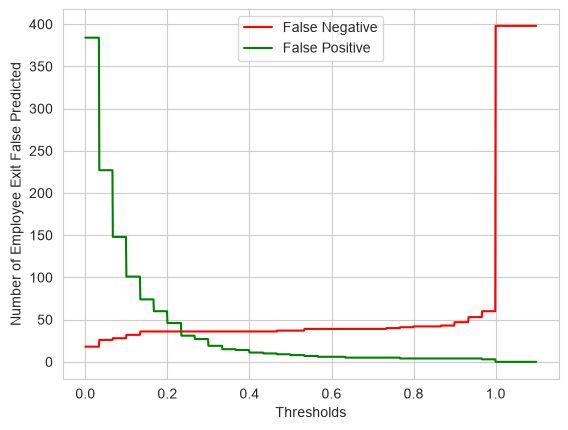

In [119]:
sns.set_style('whitegrid')

ax = sns.lineplot(data=df_threshold, x='Thresholds', y='False_Negative', label='False Negative', color='r')
ax = sns.lineplot(data=df_threshold, x='Thresholds', y='False_Positive', label='False Positive', color='g')
ax.set_ylabel('Number of Employee Exit False Predicted')

In [122]:
df_threshold[(df_threshold['Thresholds']>0.4) & (df_threshold['Thresholds']<=0.5)]

,Thresholds,True_Negative,False_Negative,True_Positive,False_Positive
401,0.401,1990,36,362,11
402,0.402,1990,36,362,11
403,0.403,1990,36,362,11
404,0.404,1990,36,362,11
405,0.405,1990,36,362,11
...,...,...,...,...,...
496,0.496,1992,37,361,9
497,0.497,1992,37,361,9
498,0.498,1992,37,361,9
499,0.499,1992,37,361,9


# Pace: Execute Stage
- Interpret model performance and results
- Share actionable steps with stakeholders



✏
## Recall evaluation metrics

- **AUC** is the area under the ROC curve; it's also considered the probability that the model ranks a random positive example more highly than a random negative example.
- **Precision** measures the proportion of data points predicted as True that are actually True, in other words, the proportion of positive predictions that are true positives.
- **Recall** measures the proportion of data points that are predicted as True, out of all the data points that are actually True. In other words, it measures the proportion of positives that are correctly classified.
- **Accuracy** measures the proportion of data points that are correctly classified.
- **F1-score** is an aggregation of precision and recall.






💭
### Reflect on these questions as you complete the executing stage.

What key insights emerged from your model(s)?\
The model able to predict eventhough the data is imbalanced. Further insights will be known after analyze feature importances.
<br><br>
What business recommendations do you propose based on the models built?\
Use the model to predict employee's exit decisions, and leverage this information to understand and retained employee.
<br><br>
Do you think your model could be improved? Why or why not? How?\
The model provides 90% recall score, which can be considered as highly accurate. Adjusting threshold, do not contributed much to the model prediction.
<br><br>
What resources do you find yourself using as you complete this stage?\
Scikit learn and Imblearn libraries


## Step 4. Results and Evaluation
- Interpret model
- Evaluate model performance using metrics
- Prepare results, visualizations, and actionable steps to share with stakeholders


In [49]:
list_feature_names = gridsearch.best_estimator_[:-2].get_feature_names_out()
list_feature_names

array(['onehot_encoding__department_IT',
       'onehot_encoding__department_RandD',
       'onehot_encoding__department_accounting',
       'onehot_encoding__department_hr',
       'onehot_encoding__department_management',
       'onehot_encoding__department_marketing',
       'onehot_encoding__department_product_mng',
       'onehot_encoding__department_sales',
       'onehot_encoding__department_support',
       'onehot_encoding__department_technical',
       'onehot_encoding__salary_high', 'onehot_encoding__salary_low',
       'onehot_encoding__salary_medium', 'scaler__average_montly_hours',
       'scale_or_none__number_project',
       'scale_or_none__time_spend_company',
       'remainder__satisfaction_level', 'remainder__last_evaluation',
       'remainder__work_accident', 'remainder__promotion_last_5years'],
      dtype=object)

#### Feature Importances

In [102]:
feature_name = []
feature_imp = []

# Collect feature importances from each tree in Bagging Classifier
importances = np.array([tree.feature_importances_ for tree in best_final_model[-1].estimators_])

# Average across trees
mean_importances = np.mean(importances, axis=0)

# Display
for name, score in zip(list_feature_names, mean_importances):
    feature_name.append(name)
    feature_imp.append(score)

df_feature_imp = pd.DataFrame(
    {'Feature name' : feature_name,
    'Feature importance' : feature_imp}
)

df_feature_imp = df_feature_imp.sort_values(by='Feature importance', ascending=False)

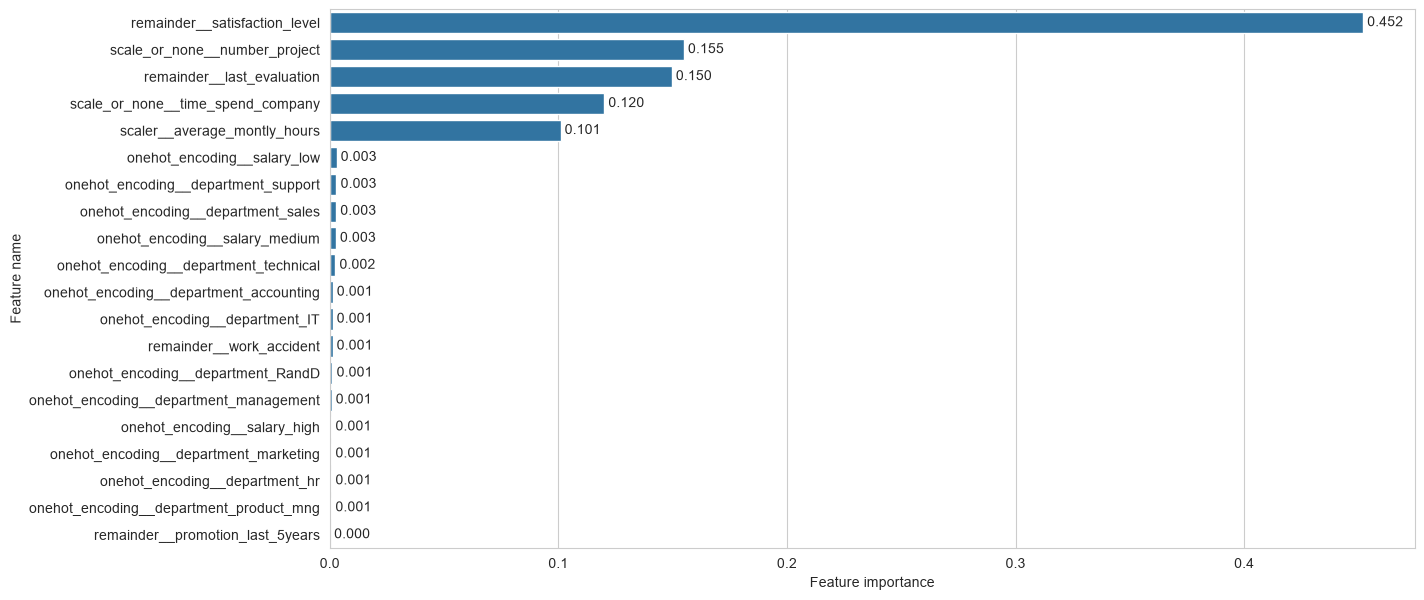

In [108]:
sns.set_style('whitegrid')
plt.figure(figsize=(14,7))
ax = sns.barplot(data=df_feature_imp, x='Feature importance', y='Feature name')
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

#### Interpretation

`satisfaction_level` contribute 45% of the model prediction\
`number_project` contribute 15% of the model prediction\
`last_evaluation` contribute 15% of the model prediction\
`time_spend_company` contribute 12% of the model prediction\
`average_monthly_hours` contribute 10% of the model prediction


#### SHAP Explainer 

In [85]:
# Manually extract steps (due to ImbPipeline)
preprocessed = best_final_model.named_steps['preprocessing']
final_model = best_final_model.named_steps['modeling']

# Transform data through preprocessing only
X_train_trf = preprocessed.fit_transform(X_train)

# Resample several data
idx_rand = np.random.choice(X_train_trf.shape[0], size=2000, replace=False )
X_train_resamp = X_train_trf[idx_rand, :]

print(X_train_resamp.data.shape)

(2000, 20)


PermutationExplainer explainer: 2001it [46:30,  1.40s/it]                           
<timed exec>:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.


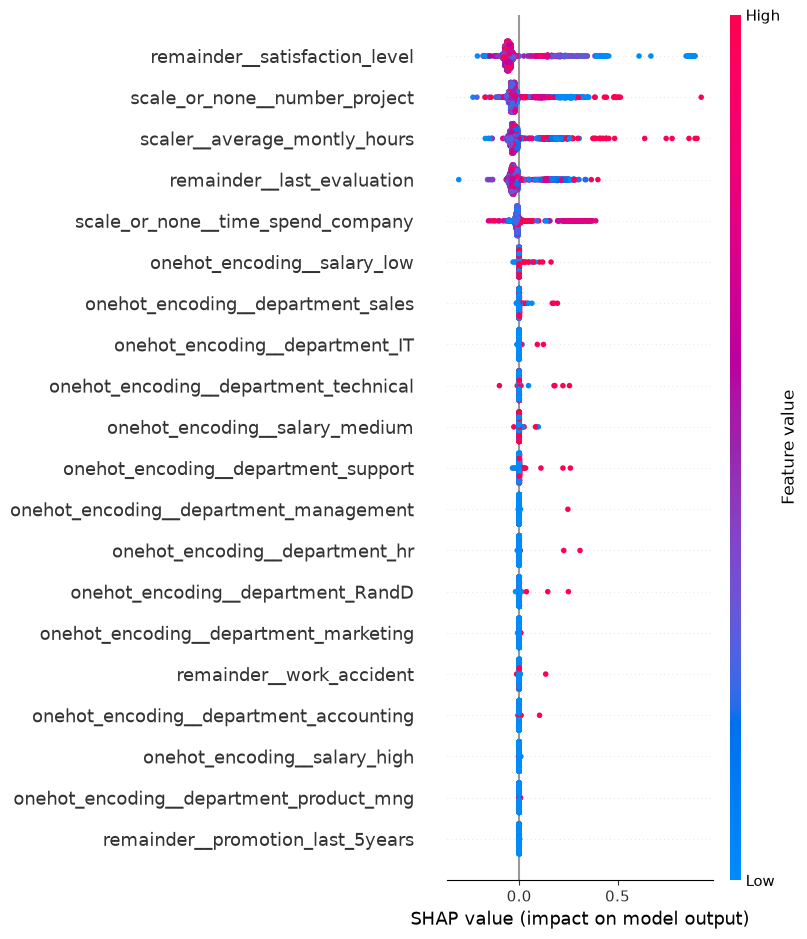

CPU times: total: 44min 55s
Wall time: 46min 31s


In [86]:
%%time
# generic Shap Explainer
explainer = shap.Explainer(final_model.predict, masker)

# Compute SHAP values for each rows in resampled X_train
shap_values = explainer(X_train_resamp)

# Plot
shap.summary_plot(shap_values, X_train_resamp, feature_names=list_feature_names, max_display=len(list_feature_names))

plt.savefig(path + "shap_summary_plot.png", bbox_inches="tight", dpi=300)

#### Interpretation (taken from 2000 samples data)

**Strongest Predictor in determine Employee will exit:**\
Low `satisfaction_level`, High `Number_project` and `Average_monthly_hours`

**Moderate Predictor:**\
`Last_evaluation` is not a strong predictor, majority of the data are on the middle left (stayed).\
`Time_spend_company` is weak-moderate predictor, although some employee with high time spend are likely to exit.

**Weak Predictor:**
Several features are weak predictors globally, with most of data are distributed in the middle. Only several on the right side (exit), with low SHAP value.\
Employee who are not from `Department` `Management, HR, RanD, Marketing, Accounting, Product Mng`

#### LIME Explainer

In [39]:
import lime
from lime import lime_tabular

In [43]:
# Define preprocessing model after tuning
preprocessor_final_model = gridsearch.best_estimator_[:-1]
preprocessor_final_model

,steps,"[('preprocessing', ...), ('resampling', ...)]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
feature_names_in_,"ndarray[object](9,)","['satisfaction_level','last_evaluation','number_project',..., 'promotion_last_5years','department','salary']"
n_features_in_,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot_encoding', ...), ('scaler', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [58]:
# Manually extract steps (due to ImbPipeline)
preprocessed = best_final_model.named_steps['preprocessing']
final_model = best_final_model.named_steps['modeling']

# Transform data through preprocessing only
X_train_trf = preprocessed.fit_transform(X_train)

# X_test only transform, no resampling
X_test_transformed = preprocessed.transform(X_test)

# Explainer based
explainer = lime_tabular.LimeTabularExplainer(
    training_data=X_train_trf,   # In numpy array
    feature_names=list_feature_names,   # Feature names 
    class_names=['Stayed', 'Left'],  # ['Class0, Class1']
    mode='classification'
)


The model must predict this customer is: Left from y_test


''

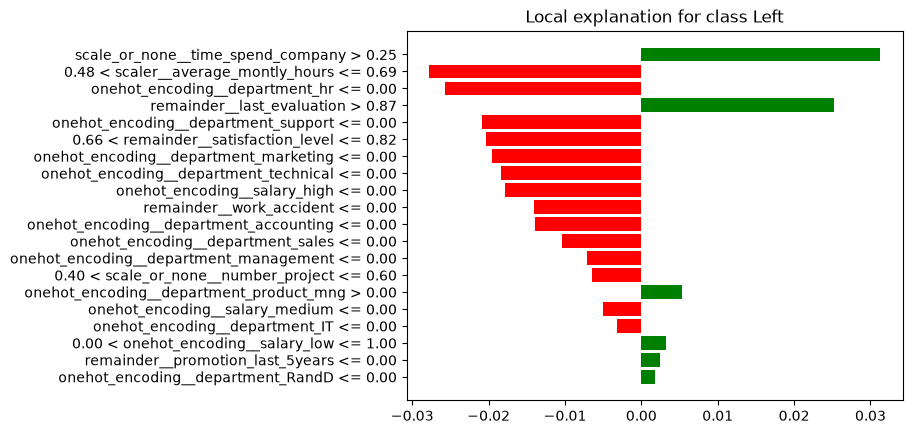

In [60]:
#LIME Explainer
idx = 12
result = y_test.iloc[idx]

print(f"The model must predict this customer is: {('Left' if result == 1 else 'Stayed')} from y_test")

exp = explainer.explain_instance(data_row= X_test_transformed[idx],    # X_test already transformed (manually, not resampling)
                                 predict_fn= best_final_model[-1].predict_proba,   # Called model only (without preprocess)
                                 num_features= 20)

exp.as_pyplot_figure()
;

#### Interpretation from LIME

As from LIME Explainer in specific row, there are several factors that contribute an Employee will left:\
`time_spend_company` and `last_evaluation` are high

Also, several factors that contribute an Employee will stay:\
employee work longer, based on `average_monthly_hours` result (after scaled),\
average employee satisfaction level, based on `satisfaction_level` result (after scaled),\
employee do not work in HR, Marketing, Technical `department` 


### Conclusion, Recommendations, Next Steps

There are several major factors that contributed why Employee left:\
Low `satisfaction_level`, High `Number_project` and High `Average_monthly_hours`\
Based on the model, `satisfaction_level` contributed 45% of the prediction process,\
while `Number_project` and `Average_monthly_hours` contributed 10-15% of the prediction process but still a strong predictor.

As a certain employee is predicted will be 'Exit',\
HR team should investigate and approach employee whether they gave low satisfaction level, so that the root cause can be investigated and resolved.\
Employee who work on lots of project might have work longer hours, thus affecting the low satisfaction level.\
HR should recommend to each department heads/managers to balance the workload for each employees.